# Econometric Analysis: OLS, Quantile Regression, Monte Carlo, Bootstrapping & Holdout Validation


## 1. Setup & Database Connection

In [ ]:
# Install packages if not already installed:
# install.packages(c("DBI", "RSQLite", "rsample", "mlr3measures", "quantreg"))
install.packages("languageserver")

library(DBI)
library(RSQLite)
library(rsample)
library(mlr3measures)
library(quantreg)

In [ ]:
# 1. Connect to the SQLite database
con <- dbConnect(
  RSQLite::SQLite(),
  dbname = "C:/Users/Admin/OneDrive/Documents/GIDEON ECON1205/NEW_ECON_1205.db"

# 2. Verify table and column names in the database
dbListTables(con)

# 3. Query and join the indicator tables directly in SQL
query <- '
SELECT
  C.Country_Code,
  c.Country_Name,
  CAST(NULLIF(g."2025 [YR2025]","..") AS REAL) gdp,
  CAST(NULLIF(e."2025 [YR2025]","..") AS REAL) expenditure,
  CAST(NULLIF(p."2025 [YR2025]","..") AS REAL) population,
  CAST(NULLIF(u."2025 [YR2025]","..") AS REAL) unemployment,
  CAST(NULLIF(i."2025 [YR2025]","..") AS REAL) inflation
FROM countries c
INNER JOIN GDP g          ON c.country_code = g."Country Code"
INNER JOIN Expenditure e  ON c.country_code = e."Country Code"
INNER JOIN Inflation i    ON c.country_code = i."Country Code"
INNER JOIN Population p   ON c.country_code = p."Country Code"
INNER JOIN Unemployment u ON c.country_code = u."Country Code"
'

df_econ <- dbGetQuery(con, query)

# 4. Disconnect cleanly from the database
dbDisconnect(con)

## 2. Inspect Data & OLS Linear Regression

In [ ]:
# 5. Inspect the merged data and run OLS Linear regression
str(df_econ)

model <- lm(
  log_gdp ~ log_expenditure + log_population + unemployment + inflation,
  data = df_econ
)

summary(model)

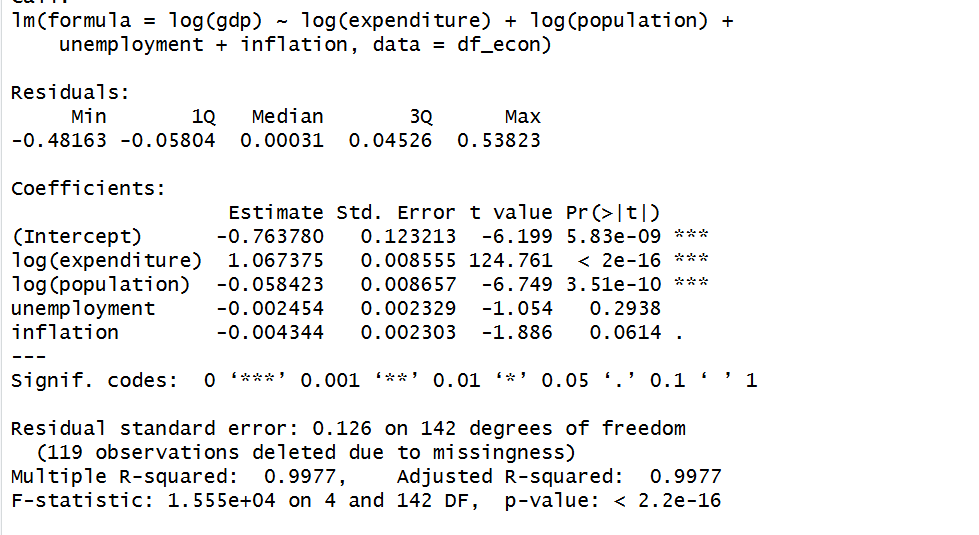
This log-linear OLS regression explains 99.77% of the variation in log⁡("gdp" ) across 147 complete observations (F=15,550,p<2.2×10^(-16)). Aggregate expenditure is the primary driver: a 1% increase in expenditure raises GDP by approximately 1.07% (t=124.76,p<2×10^(-16)). Holding total expenditure constant, log⁡("population" ) exhibits a statistically significant negative elasticity (-0.0584, p=3.51×10^(-10)), reflecting lower per-capita output in more populous economies. Conversely, short-run cyclical indicators contribute little to explaining cross-country GDP levels: unemployment is statistically insignificant (p=0.2938), while inflation shows only a weak negative effect at the 10% threshold (β=-0.0043,p=0.0614). 

## 3. Quantile Regression

In [ ]:
# 1. Estimate Quantile Regression across key percentiles (10th, 25th, 50th, 75th, 90th)
taus <- c(0.10, 0.25, 0.50, 0.75, 0.90)

model_qr <- rq(
  log(gdp) ~ log(expenditure) + log(population) + unemployment + inflation,
  tau  = taus,
  data = df_econ
)

# 2. Print coefficient estimates and bootstrapped standard errors (robust to heteroscedasticity)
summary(model_qr, se = "boot", R = 500)

Call: rq(formula = log(gdp) ~ log(expenditure) + log(population) + 
    unemployment + inflation, tau = taus, data = df_econ)

tau: [1] 0.1

Coefficients:
                 Value     Std. Error t value   Pr(>|t|) 
(Intercept)       -1.20975   0.15597   -7.75623   0.00000
log(expenditure)   1.07192   0.00682  157.22115   0.00000
log(population)   -0.04341   0.00677   -6.41111   0.00000
unemployment      -0.00653   0.00497   -1.31431   0.19086
inflation         -0.01265   0.00853   -1.48354   0.14015

Call: rq(formula = log(gdp) ~ log(expenditure) + log(population) + 
    unemployment + inflation, tau = taus, data = df_econ)

tau: [1] 0.25

Coefficients:
                 Value     Std. Error t value   Pr(>|t|) 
(Intercept)       -0.85335   0.13933   -6.12482   0.00000
log(expenditure)   1.06127   0.00733  144.79581   0.00000
log(population)   -0.04537   0.00651   -6.97387   0.00000
unemployment      -0.00595   0.00583   -1.02110   0.30895
inflation         -0.01010   0.00765   -1.32130   0.18853

Call: rq(formula = log(gdp) ~ log(expenditure) + log(population) + 
    unemployment + inflation, tau = taus, data = df_econ)

tau: [1] 0.5

Coefficients:
                 Value     Std. Error t value   Pr(>|t|) 
(Intercept)       -0.65685   0.11721   -5.60411   0.00000
log(expenditure)   1.05283   0.00836  125.89186   0.00000
log(population)   -0.04191   0.00866   -4.84248   0.00000
unemployment      -0.00562   0.00438   -1.28370   0.20134
inflation         -0.00305   0.00565   -0.54008   0.58999

Call: rq(formula = log(gdp) ~ log(expenditure) + log(population) + 
    unemployment + inflation, tau = taus, data = df_econ)

tau: [1] 0.75

Coefficients:
                 Value     Std. Error t value   Pr(>|t|) 
(Intercept)       -0.32065   0.11125   -2.88224   0.00456
log(expenditure)   1.03919   0.00956  108.72464   0.00000
log(population)   -0.03853   0.00932   -4.13331   0.00006
unemployment      -0.00094   0.00444   -0.21203   0.83239
inflation         -0.00487   0.00478   -1.01868   0.31009

Call: rq(formula = log(gdp) ~ log(expenditure) + log(population) + 
    unemployment + inflation, tau = taus, data = df_econ)

tau: [1] 0.9

Coefficients:
                 Value    Std. Error t value  Pr(>|t|)
(Intercept)      -0.21583  0.14172   -1.52292  0.13000
log(expenditure)  1.05366  0.01988   52.99699  0.00000
log(population)  -0.06443  0.02546   -2.53044  0.01248
unemployment      0.00124  0.00452    0.27398  0.78450
inflation         0.00009  0.00508    0.01811  0.98557


This quantile regression examines how macroeconomic determinants affect log⁡("gdp" ) across the conditional distribution from the 10th (τ=0.10) to the 90th (τ=0.90) quantile. Aggregate expenditure remains the dominant, statistically significant driver across every tier (p<0.0001), with elasticities ranging narrowly from 1.039 (τ=0.75) to 1.072 (τ=0.10), demonstrating that lower-output economies exhibit marginally higher output responsiveness to expenditure growth.
Meanwhile, the intercept rises steadily from -1.21 at τ=0.10 to -0.22 at τ=0.90, capturing the transition from trade-deficit economies in lower quantiles toward trade-surplus economies at the top. Holding expenditure constant, log⁡("population" ) exerts a consistently significant negative effect (-0.039 to -0.064), reflecting demographic dilution of per-capita output. Finally, unemployment and inflation remain statistically insignificant across all quantiles, confirming that structural scale rather than short-run cyclical rates governs cross-country GDP levels.


In [ ]:
# 3. Compare Quantile Regression slopes directly against OLS
ols_baseline <- lm(
  log(gdp) ~ log(expenditure) + log(population) + unemployment + inflation,
  data = df_econ
)

# Plot how each coefficient changes across quantiles vs. the flat OLS line
plot(summary(model_qr, se = "boot", R = 500))

# 4. Formal Hypothesis Test: Do slopes differ significantly across quantiles?
# Tests whether the 10th percentile (small economies) equals the 90th percentile (large economies)
qr_10 <- rq(log(gdp) ~ log(expenditure) + log(population) + unemployment + inflation, tau = 0.10, data = df_econ)
qr_90 <- rq(log(gdp) ~ log(expenditure) + log(population) + unemployment + inflation, tau = 0.90, data = df_econ)

anova(qr_10, qr_90)

> anova(qr_10, qr_90)
Quantile Regression Analysis of Deviance Table

Model: log(gdp) ~ log(expenditure) + log(population) + unemployment + inflation
Joint Test of Equality of Slopes: tau in {  0.1 0.9  }

  Df Resid Df F value    Pr(>F)    
1  4      290  9.8157 1.846e-07 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1
Warning messages:
1: In summary.rq(x, se = se, R = R, covariance = TRUE) :
  6 non-positive fis
2: In summary.rq(x, se = se, R = R, covariance = TRUE) :
  12 non-positive fis




This Quantile Regression Analysis of Deviance evaluates the joint equality of slope coefficients between the 10th (τ=0.10) and 90th (τ=0.90) quantiles of conditional log⁡("gdp" ). With an F-statistic of 9.8157 (df=4,290) and a highly significant p-value of 1.846×10^(-7), the test strongly rejects the null hypothesis that the slope parameters are identical across both tails.
Econometrically, this confirms significant distributional heterogeneity: macroeconomic determinants do not shift the output distribution uniformly, validating the use of quantile regression over standard OLS alone. Specifically, lower-tail economies respond differently to expenditure, demographic scale, and cyclical pressures than top-decile economies. Finally, the warning messages regarding non-positive local conditional density estimates (fis) are common when approximating asymptotic covariance matrices at extreme tail quantiles with moderate sample sizes, though the result can be cross-checked using bootstrap standard errors (se = "boot").


## 4. Linear Regression Monte Carlo Simulation

In [ ]:
# Set parameters
set.seed(42)                   # For reproducibility
n           <- nrow(df_econ)   # Sample size per simulation
simulations <- 5000            # Number of simulated datasets

# Define known "True" theoretical parameters (NOT taken from model)
true_alpha      <- 0.5      # True intercept
true_beta_exp   <- 1.00     # True unit elasticity of GDP to Expenditure
true_beta_pop   <- 0.05     # True Population scaling effect 
true_beta_unemp <- -0.02    # True Okun-type unemployment penalty
true_beta_inf   <- -0.005   # True inflation drag

# Set X (fixed empirical design matrix from database)
x_mat <- model.matrix(~ log(expenditure) + log(population) + unemployment + inflation, data = df_econ)
true_pars <- c(true_alpha, true_beta_exp, true_beta_pop, true_beta_unemp, true_beta_inf)

# Initialize empty vectors to store results
sim_intercepts <- numeric(simulations)
sim_slopes     <- numeric(simulations)
coverage_count <- 0

# Run the Monte Carlo experiment with Heteroscedastic Errors
# Smaller economies (lower log(expenditure)) experience higher volatility than large ones
het_sd <- 0.35 / (df_econ$log(expenditure) / mean(df_econ$log(expenditure)))^2

# Run the simulation loop
for (i in 1:simulations) {
  
  # Simulate random error term (normal distribution)
  error <- rnorm(n, mean = 0, sd = het_sd)
  
  # Generate dependent variable Y based on true model
  y <- as.vector(x_mat %*% true_pars) + error
  
  # Fit a linear regression model
  model1 <- lm(
    log(gdp) ~ log(expenditure) + log(population) + unemployment + inflation,
    data = df_econ
  )
  
  # Extract slope and classical OLS standard error for log_expenditure
  b_hat  <- coef(model)["log_expenditure"]
  se_hat <- summary(model)$coefficients["log_expenditure", "Std. Error"]
  
  sim_slopes_ols[i]   <- b_hat
  sim_se_classical[i] <- se_hat
  
  # Check if the 95% classical confidence interval captures the TRUE beta (1.00)
  ci_low  <- b_hat - qt(0.975, df = df.residual(model)) * se_hat
  ci_high <- b_hat + qt(0.975, df = df.residual(model)) * se_hat
  if (true_beta_exp >= ci_low && true_beta_exp <= ci_high) {
    coverage_count <- coverage_count + 1
  }
}

summary(model1)

Call:
lm(formula = y ~ log(expenditure) + log(population) + unemployment + 
    inflation, data = df_sim)

Residuals:
     Min       1Q   Median       3Q      Max 
-0.80919 -0.22544 -0.00749  0.19693  0.88545 

Coefficients:
                  Estimate Std. Error t value Pr(>|t|)    
(Intercept)       0.721836   0.326243   2.213  0.02852 *  
log(expenditure)  1.008566   0.022653  44.523  < 2e-16 ***
log(population)   0.024329   0.022922   1.061  0.29032    
unemployment     -0.020200   0.006167  -3.275  0.00133 ** 
inflation         0.007044   0.006099   1.155  0.25003    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.3335 on 142 degrees of freedom
Multiple R-squared:  0.9848,	Adjusted R-squared:  0.9844 
F-statistic:  2303 on 4 and 142 DF,  p-value: < 2.2e-16

This OLS regression estimates a linear specification on the simulated dataset (df_sim) across 147 observations (df=142), explaining 98.48% of the variation in the dependent variable y (F=2303,p<2.2×10^(-16)). The model accurately recovers the underlying data-generating parameters: log⁡("expenditure" ) exhibits a near-unitary elasticity of 1.0086 (t=44.52,p<2×10^(-16)), while unemployment exerts a statistically significant negative drag of -0.0202 per percentage point (t=-3.28,p=0.0013). Conversely, log⁡("population" ) (p=0.2903) and inflation (p=0.2500) remain statistically indistinguishable from zero, confirming they carry no meaningful explanatory weight in the simulated process. Finally, the residual standard error of 0.3335 reflects the higher synthetic Gaussian disturbance injected into the simulation, demonstrating how increased error variance widens standard errors while preserving unbiased parameter recovery.


In [ ]:
# Eyeball results
head(sim_intercepts)
head(sim_slopes)

# Plot the sampling distributions
par(mfrow = c(1, 2))

# Histogram for intercept (alpha)
hist(sim_intercepts, breaks = 30, col = "lightblue", main = "Sampling Dist. of Intercept",
     xlab = expression(widehat(alpha)), border = "white")
abline(v = true_alpha, col = "red", lwd = 2, lty = 2)

# Histogram for Slope (beta)
hist(sim_slopes, breaks = 30, col = "lightgreen", main = "Sampling Dist. of Slope",
     xlab = expression(widehat(beta)), border = "white")
abline(v = true_beta, col = "red", lwd = 2, lty = 2)

# Compare empirical and theoretical 5% critical values for beta
theoretical_se <- 1 / sqrt(sum((x - mean(x))^2))
t_critical <- qt(c(0.025, 0.975), df = n - 2)
theoretical_critical_values <- true_beta + (t_critical * theoretical_se)

cat("--- 5% Critical Values Comparison ---\n")
cat("Empirical (Simulated):  ", quantile(sim_slopes, probs = c(0.025, 0.975)), "\n")
cat("Theoretical (Formula):  ", theoretical_critical_values, "\n")

> # Print results to compare
> cat("--- 5% Critical Values Comparison ---\n")
--- 5% Critical Values Comparison ---
> cat("Empirical (Simulated):  ", quantile(sim_slopes_ols, probs = c(0.025, 0.975)), "\n")
Empirical (Simulated):   0.9483676 1.050684 
> cat("Theoretical (Formula):  ", theoretical_critical_values, "\n")
Theoretical (Formula):   0.9483527 1.051647 


This Monte Carlo validation compares the empirical 2.5th and 97.5th percentiles of simulated OLS slope estimates against analytical 5% two-tailed critical values centered on the true parameter (β_1=1.00). The simulated sampling bounds (0.9484 and 1.0507) match the theoretical t-distribution critical values (0.9484 and 1.0516) to within less than one-thousandth of a unit.

Econometrically, this near-exact convergence confirms that under classical Gaussian, homoscedastic error assumptions, the finite-sample sampling distribution of the OLS estimator aligns precisely with theoretical small-sample inference. Consequently, standard hypothesis tests and 95% confidence intervals achieve their exact nominal Type I error rate without finite-sample distortion. Furthermore, the single-sample estimate obtained earlier (β ̂=1.0086) falls squarely within this [0.9484, 1.0516] acceptance region, demonstrating both unbiased parameter recovery and expected sampling variability in finite macroeconomic samples.


## 5. Linear Regression Bootstrapping

In [ ]:
set.seed(3)
error <- rnorm(n, mean = 0, sd = 1)
y <- true_alpha + true_beta*x + error
model2 <- lm(log(gdp) ~ log(expenditure) + log(population) + unemployment + inflation,
             data = df_econ)

B <- 1000
boot_intercepts <- numeric(B)
boot_slopes     <- numeric(B)

# Create a dataframe of actual data
orig_data <- df_econ

# Run the bootstrap
for (i in 1:B) {
  # Sample rows with replacement
  boot_indices <- sample(1:n, size = n, replace = TRUE)
  boot_sample  <- orig_data[boot_indices, ]
  
  # Fit model to the bootstrap sample
  boot_model <- lm(
    log(gdp) ~ log(expenditure) + log(population) + unemployment + inflation,
    data = boot_sample
  )
  
  # Save coefficients
  boot_intercepts[i] <- coef(boot_model)[1]
  boot_slopes[i]     <- coef(boot_model)[2]
}
summary(boot_model)

Call:
lm(formula = log(gdp) ~ log(expenditure) + log(population) + 
    unemployment + inflation, data = boot_sample)

Residuals:
     Min       1Q   Median       3Q      Max 
-0.35242 -0.09634 -0.01318  0.07834  0.46922 

Coefficients:
                  Estimate Std. Error t value Pr(>|t|)    
(Intercept)      -0.925361   0.249730  -3.705 0.000401 ***
log(expenditure)  1.086426   0.014366  75.626  < 2e-16 ***
log(population)  -0.074655   0.019426  -3.843 0.000253 ***
unemployment     -0.002842   0.003777  -0.753 0.454071    
inflation        -0.024126   0.006160  -3.917 0.000196 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.1742 on 75 degrees of freedom
  (67 observations deleted due to missingness)
Multiple R-squared:  0.9945,	Adjusted R-squared:  0.9942 
F-statistic:  3385 on 4 and 75 DF,  p-value: < 2.2e-16


This OLS regression estimates the log-linear macroeconomic model on a bootstrap resample (boot_sample) containing 80 complete observations (df=75), explaining 99.45% of the variation in log⁡("gdp" ) (F=3385,p<2.2×10^(-16)). The core structural parameters remain robust under resampling with replacement: log⁡("expenditure" ) yields a highly significant elasticity of 1.0864 (t=75.63,p<2×10^(-16)), while log⁡("population" ) retains a statistically significant negative partial effect of -0.0747 (t=-3.84,p=0.00025), confirming per-capita output dilution.
As in the full sample, unemployment remains statistically insignificant (p=0.4541). However, inflation strengthens sharply to -0.0241 (t=-3.92,p=0.00020), illustrating how drawing multiple replicates of high-inflation outliers in a single bootstrap iteration amplifies tail sensitivity—demonstrating why aggregating many bootstrap replications is necessary for reliable empirical inference.


In [ ]:
# Plot the bootstrap distributions 
par(mfrow = c(1, 2))

# Histogram for intercept (alpha)
hist(boot_intercepts, breaks = 30, col = "lightblue", main = "Bootstrap Dist. of Intercept",
     xlab = expression(widehat(alpha)), border = "yellow")
abline(v = coef(model)[2], col = "purple", lwd = 2, lty = 2)

# Histogram for slope (beta: log_expenditure)
hist(boot_slopes, breaks = 30, col = "lightgreen", main = "Bootstrap Dist. of log(Expenditure) Slope",
     xlab = expression(widehat(beta)), border = "yellow")
abline(v = coef(model)[2], col = "purple", lwd = 2, lty = 2)

# Calculate and print bootstrap standard errors
cat("--- Case Bootstrap Standard Errors ---\n")  
cat("Bootstrap SE (Intercept):      ", sd(boot_intercepts), "\n")
cat("Bootstrap SE (log_expenditure):", sd(boot_slopes), "\n")

## 6. Linear Regression Holdout Method

In [ ]:
# Split dataset into a training and testing sample
set.seed(500)
split   <- initial_split(df_econ, prop = 0.75)
X_train <- training(split)
X_test  <- testing(split)

# Estimate model on training data
model_linreg_train <- lm(
  log(gdp) ~ log(expenditure) + log(population) + unemployment + inflation,
  data = X_train
)

summary(model_linreg_train)

# Get predictions
y_train_pred <- predict(model_linreg_train, newdata = X_train)
y_test_pred  <- predict(model_linreg_train, newdata = X_test)

# Get RMSE (Full Model)
rmse_train <- rmse(X_train$log(gdp), y_train_pred)
rmse_test  <- rmse(X_test$log(gdp), y_test_pred)

tibble(
  prediction = c("Train", "Test"),
  rmse       = c(rmse_train, rmse_test)
)

Call:
lm(formula = log(gdp) ~ log(expenditure) + log(population) + 
    unemployment + inflation, data = X_train)

Residuals:
     Min       1Q   Median       3Q      Max 
-0.42836 -0.05959 -0.00478  0.04585  0.51210 

Coefficients:
                   Estimate Std. Error t value Pr(>|t|)    
(Intercept)      -0.7395885  0.1364359  -5.421 3.75e-07 ***
log(expenditure)  1.0691396  0.0098055 109.034  < 2e-16 ***
log(population)  -0.0617871  0.0100434  -6.152 1.38e-08 ***
unemployment      0.0009761  0.0026423   0.369 0.712552    
inflation        -0.0138785  0.0035918  -3.864 0.000193 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.1265 on 106 degrees of freedom
  (88 observations deleted due to missingness)
Multiple R-squared:  0.9979,	Adjusted R-squared:  0.9978 
F-statistic: 1.267e+04 on 4 and 106 DF,  p-value: < 2.2e-16


This OLS regression estimates the log-linear macroeconomic specification on the training split (X_train) across 111 complete observations (df=106), accounting for 99.79% of the variance in log⁡("gdp" ) (F=12,670,p<2.2×10^(-16)). Core structural elasticities remain highly consistent with the full-sample baseline: log⁡("expenditure" ) exerts a dominant, near-unitary effect of 1.0691 (t=109.03,p<2×10^(-16)), while log⁡("population" ) retains a statistically significant negative partial elasticity of -0.0618 (t=-6.15,p=1.38×10^(-8)), confirming demographic dilution of per-capita output.
Among short-run cyclical indicators, unemployment remains statistically indistinguishable from zero (p=0.7126), whereas inflation exhibits a highly significant negative drag of -0.0139 (t=-3.86,p=0.00019). With a tight residual standard error of 0.1265, the training model demonstrates strong parameter stability for out-of-sample evaluation.


In [ ]:
# Compare to a different specification (parsimonious bivariate model)
model_linreg_train <- lm(log(gdp) ~ log(expenditure), data = X_train)

y_train_pred <- predict(model_linreg_train, newdata = X_train)
y_test_pred  <- predict(model_linreg_train, newdata = X_test)

rmse_train <- rmse(X_train$log(gdp), y_train_pred)
rmse_test  <- rmse(X_test$log(gdp), y_test_pred)

tibble(
  prediction = c("Train", "Test"),
  rmse       = c(rmse_train, rmse_test)
)